# Task 1: Negative Binomial Probabilities

## Given parameters

- Assignment selector: $\xi_1 = 2$.
- Negative binomial parameter: $k = \xi_2 = 86$.
- Success probability: $p = \xi_3 = 0.16$.
- Complementary probability: $q = 1-p = 0.84$.

## Objectives

1. Define the assigned probability distribution.
2. Calculate its expectation and median.
3. Plot its probability mass function and indicate the expectation and median.
4. Establish a cutoff beyond which every individual probability is below 0.5%.
5. Justify the calculations and document how they can be reproduced.

## Parameter interpretation

The course book defines the negative binomial distribution as the number of failures before the kth success, with success probability p.

This notebook provisionally follows that convention: k = 86 is the success-count parameter, not the expectation.

The assignment describes k as an "expectation", which conflicts with the course-book definition.

## Probability model

Let $X$ denote the number of meteorites falling into the ocean during one year.

Under the course-book parameter convention, the assigned model is

$$
X \sim \operatorname{NB}(k=86,\ p=0.16).
$$

Its support is

$$
x \in \{0,1,2,\ldots\}.
$$

The probability mass function is

$$
P(X=x)
=
\binom{x+k-1}{x}p^k(1-p)^x.
$$

Substituting the assigned parameters gives

$$
P(X=x)
=
\binom{x+85}{x}(0.16)^{86}(0.84)^x.
$$

The failures-before-successes convention specifies the mathematical parameterization. It does not require interpreting meteorite arrivals literally as a sequence of Bernoulli successes and failures.

In [1]:
# Task 1 parameters.
# number of failures before the kth success

k = 86
p = 0.16
q = 1 - p

# Basic param check
assert isinstance(k, int) and k > 0
assert 0 < p < 1

# Course-book formulas
expected_count = k * q / p
variance_count = k * q / p**2

print(f"k = {k}")
print(f"p = {p:.2f}")
print(f"q = {q:.2f}")
print(f"Expected annual count = {expected_count:.4f}")
print(f"Variance = {variance_count:.4f}")

k = 86
p = 0.16
q = 0.84
Expected annual count = 451.5000
Variance = 2821.8750


## Expectation

Using the expectation formula for the chosen negative binomial convention,

$$
E[X]
=
\frac{k(1-p)}{p}
=
\frac{86(0.84)}{0.16}
=
451.5.
$$

Under this model, the long-run average annual meteorite count is 451.5.
The expectation need not be an integer, although each observed annual count must be an integer.

For an additional computational check, the variance is

$$
\operatorname{Var}(X)
=
\frac{k(1-p)}{p^2}
=
\frac{86(0.84)}{0.16^2}
=
2821.875.
$$

The variance is recorded as supporting information.

## Median

For this discrete distribution, the lower median is defined as

$$
m=\min\{x\in\mathbb{N}_0:F(x)\geq0.5\},
$$

where

$$
F(x)=P(X\leq x)=\sum_{j=0}^{x}P(X=j).
$$

The median can therefore be found by accumulating probabilities until the cumulative probability first reaches or exceeds 0.5.

To calculate consecutive probabilities, the probability mass function gives

$$
\frac{P(X=x+1)}{P(X=x)}
=
\frac{x+k}{x+1}(1-p).
$$

Consequently,

$$
P(X=x+1)
=
P(X=x)\frac{x+k}{x+1}(1-p),
$$

starting from

$$
P(X=0)=p^k.
$$

This recurrence allows the cumulative probabilities to be calculated without repeatedly evaluating binomial coefficients.

In [2]:
x = 0
probability = p**k
cumulative_probability = probability
cdf_before = 0.0

# first integer where F(x) >= 0.5
while cumulative_probability < 0.5:
    cdf_before = cumulative_probability

    # convert P(X=x) into P(X=x+1)
    probability *= ((x + k) / (x + 1)) * q

    x += 1
    cumulative_probability += probability

median_count = x
cdf_at_median = cumulative_probability

# verify defining condition of the lower median
assert cdf_before < 0.5 <= cdf_at_median

print(f"Median = {median_count}")
print(f"F({median_count - 1}) = {cdf_before:.7f}")
print(f"F({median_count}) = {cdf_at_median:.7f}")

Median = 450
F(449) = 0.4993633
F(450) = 0.5068858


### Median result

The cumulative probabilities are

$$
F(449)\approx0.4993633
$$

and

$$
F(450)\approx0.5068858.
$$

Since

$$
F(449)<0.5\leq F(450),
$$

the lower median is

$$
\boxed{m=450}.
$$

Under the model, the probability of observing at most 450 meteorites during a year is approximately 50.69%. The cumulative probability at 449 is still below 50%.

## Upper probability cutoff

The task requires identifying an upper cutoff beyond which every individual probability remains below 0.5%, or 0.005.

Finding one probability below this threshold is insufficient: the probabilities for all larger counts must also remain below it.

Using the probability recurrence,

$$
\frac{P(X=x+1)}{P(X=x)}
=
0.84\frac{x+86}{x+1}.
$$

The probabilities decrease whenever this ratio is less than one:

$$
0.84\frac{x+86}{x+1}<1.
$$

Because $x+1>0$, this is equivalent to

$$
0.84(x+86)<x+1,
$$

and hence

$$
71.24<0.16x,
$$

which gives

$$
x>445.25.
$$

Therefore, for every integer $x\geq446$,

$$
P(X=x+1)<P(X=x).
$$

Once a probability in this decreasing region falls below 0.005, all subsequent probabilities must also be below 0.005.

In [3]:
from math import comb, floor

def meteorite_pmf(x):
    """Probability of x failures before k successes."""
    if x < 0:
        return 0.0

    return comb(x + k - 1, x) * p**k * q**x


threshold = 0.005

# probabilities decrease from this integer onward
decreasing_start = floor((q * k - 1) / p) + 1

# search only in the decreasing region
# starting at zero would incorrectly select a tiny lower-tail probability
cutoff = decreasing_start

while meteorite_pmf(cutoff) >= threshold:
    cutoff += 1

probability_before_cutoff = meteorite_pmf(cutoff - 1)
probability_at_cutoff = meteorite_pmf(cutoff)

assert probability_before_cutoff >= threshold
assert probability_at_cutoff < threshold

# calculate the probability omitted if a graph stops at the cutoff
cdf_at_cutoff = sum(
    meteorite_pmf(value)
    for value in range(cutoff + 1)
)

tail_after_cutoff = 1 - cdf_at_cutoff

print(f"Decreasing region begins at x = {decreasing_start}")
print(f"First upper-tail count below 0.5% = {cutoff}")
print(
    f"P(X = {cutoff - 1}) = "
    f"{probability_before_cutoff:.8f}"
)
print(
    f"P(X = {cutoff}) = "
    f"{probability_at_cutoff:.8f}"
)
print(
    f"P(X > {cutoff}) = "
    f"{tail_after_cutoff:.6f} "
    f"({100 * tail_after_cutoff:.2f}%)"
)

Decreasing region begins at x = 446
First upper-tail count below 0.5% = 496
P(X = 495) = 0.00502105
P(X = 496) = 0.00494047
P(X > 496) = 0.195350 (19.53%)


### Cutoff result

The probabilities around the upper threshold are

$$
P(X=495)\approx0.00502105>0.005
$$

and

$$
P(X=496)\approx0.00494047<0.005.
$$

The probability mass function is decreasing throughout this region.
Therefore,

$$
\boxed{P(X=x)<0.005\quad\text{for every integer }x\geq496.}
$$

This condition concerns each individual probability, not the combined probability of the entire remaining tail.

In fact,

$$
P(X>496)\approx0.195350.
$$

A graph ending at 496 would therefore omit approximately 19.53% of the total probability. To show the distribution more completely, the visualization will extend beyond 496 while marking this individual-probability threshold explicitly.

## Visualization

The probability mass function is displayed using one bar for each nonnegative integer count.

The plotted range extends to the smallest integer U for which

$$
P(X\leq U)\geq0.999.
$$

This displays at least 99.9% of the total probability without renormalizing the displayed probabilities.

The graph marks:

- The expectation, $E[X]=451.5$.
- The median, $m=450$.
- The probability threshold, $0.005=0.5\%$.
- The upper-tail count $496$, from which every individual probability
  remains below the threshold.

The mean and median are close together, so their exact values are also stated in the legend.

In [4]:
from math import isclose

# smallest upper endpoint containing at least 99.9%
# of the probability, using the recurrence derived earlier
coverage_target = 0.999

plot_upper = 0
current_probability = p**k
plot_probabilities = [current_probability]
plot_coverage = current_probability

while plot_coverage < coverage_target:
    current_probability *= (
        (plot_upper + k) / (plot_upper + 1)
    ) * q

    plot_upper += 1
    plot_probabilities.append(current_probability)
    plot_coverage += current_probability

plot_counts = list(range(plot_upper + 1))
omitted_probability = 1 - plot_coverage

# endpoint check and comparsion of the two calculation methods
assert plot_coverage >= coverage_target
assert plot_coverage - plot_probabilities[-1] < coverage_target

for value in (0, median_count, cutoff, plot_upper):
    assert isclose(
        plot_probabilities[value],
        meteorite_pmf(value),
        rel_tol=1e-10,
        abs_tol=1e-15,
    )

print(f"Plotted counts: 0 to {plot_upper}")
print(f"Probability displayed: {100 * plot_coverage:.5f}%")
print(f"Probability omitted: {100 * omitted_probability:.5f}%")
print("Recurrence and direct PMF calculations agree.")

Plotted counts: 0 to 632
Probability displayed: 99.90181%
Probability omitted: 0.09819%
Recurrence and direct PMF calculations agree.


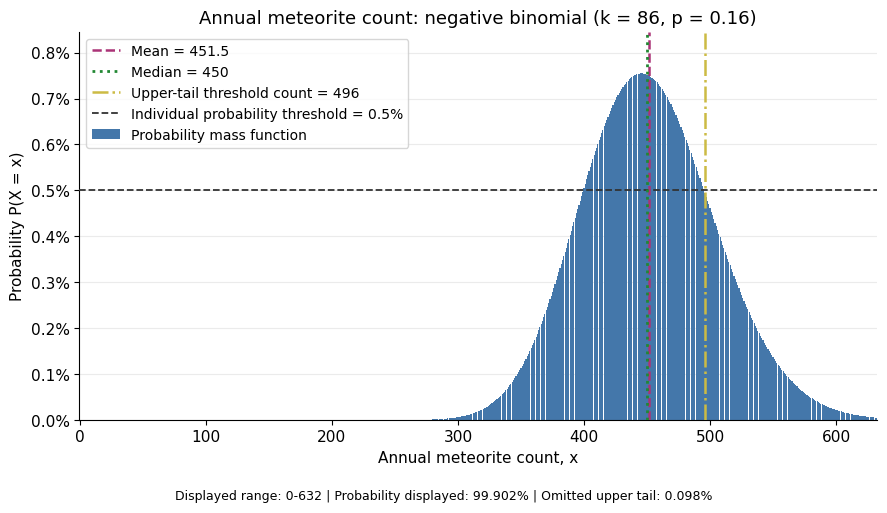

Matplotlib version: 3.7.2
PDF saved to: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task01_negative_binomial.pdf
PNG saved to: C:\Users\Usuario\Documents\DocsMain\Informatik\ComputerScienceMSc\advStatistics\workbook\figures\task01_negative_binomial.png


In [5]:
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# output folder inside the current wd
figure_directory = Path("figures")
figure_directory.mkdir(parents=True, exist_ok=True)

with plt.rc_context({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "pdf.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(9, 5.2))

    # each bar represents one individual count probability
    ax.bar(
        plot_counts,
        plot_probabilities,
        width=0.9,
        color="#4477AA",
        edgecolor="none",
        label="Probability mass function",
        zorder=2,
    )

    ax.axvline(
        expected_count,
        color="#AA3377",
        linestyle="--",
        linewidth=1.8,
        label=f"Mean = {expected_count:.1f}",
        zorder=4,
    )

    ax.axvline(
        median_count,
        color="#228833",
        linestyle=":",
        linewidth=2,
        label=f"Median = {median_count}",
        zorder=4,
    )

    ax.axvline(
        cutoff,
        color="#CCBB44",
        linestyle="-.",
        linewidth=1.8,
        label=f"Upper-tail threshold count = {cutoff}",
        zorder=4,
    )

    ax.axhline(
        threshold,
        color="#333333",
        linestyle="--",
        linewidth=1.3,
        label="Individual probability threshold = 0.5%",
        zorder=3,
    )

    ax.set_title(
        f"Annual meteorite count: negative binomial "
        f"(k = {k}, p = {p:.2f})"
    )
    ax.set_xlabel("Annual meteorite count, x")
    ax.set_ylabel("Probability P(X = x)")

    # probability axis as percentages:
    # 0.005 is displayed as 0.5%
    ax.yaxis.set_major_formatter(
        PercentFormatter(xmax=1, decimals=1)
    )

    ax.set_xlim(-0.5, plot_upper + 0.5)
    ax.set_ylim(0, max(plot_probabilities) * 1.12)

    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(loc="upper left", frameon=True)

    fig.text(
        0.5,
        0.025,
        f"Displayed range: 0-{plot_upper} | "
        f"Probability displayed: {100 * plot_coverage:.3f}% | "
        f"Omitted upper tail: {100 * omitted_probability:.3f}%",
        ha="center",
        fontsize=9,
    )

    fig.tight_layout(rect=(0, 0.06, 1, 1))

    pdf_path = figure_directory / "task01_negative_binomial.pdf"
    png_path = figure_directory / "task01_negative_binomial.png"

    fig.savefig(pdf_path, bbox_inches="tight")
    fig.savefig(png_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)

print(f"Matplotlib version: {matplotlib.__version__}")
print(f"PDF saved to: {pdf_path.resolve()}")
print(f"PNG saved to: {png_path.resolve()}")

**Figure 1.** Probability mass function of the negative binomial model with success-count parameter $k=86$ and success probability $p=0.16$. Each bar represents the probability of one annual meteorite count. The expectation, median, and upper-tail threshold count are marked. For every integer $x\geq496$, the individual probability is below 0.5%. The displayed range, $0\leq x\leq632$, contains approximately 99.902% of the total probability. Source: author's calculations.

## Interpretation

Under the stated negative binomial parameterization, the expected annual meteorite count is 451.5 and the median is 450. The expectation describes the long-run average, while the median identifies where the cumulative probability first reaches 50%.

Every individual count of 496 or more has probability below 0.5%. However, the combined probability of observing more than 496 meteorites is approximately 19.53%. Small probabilities for individual counts therefore do not imply that the entire upper tail is unlikely.